
Feature Selection Comparison
Mục tiêu của Notebook này:

Dùng LASSO (L1 Regularization) để lọc bớt các gene nhiễu từ 211 gene ban đầu, lấy ra  K  gene quan trọng nhất.
Sử dụng số lượng  K  này để chọn Top  K  gene theo các phương pháp: ANOVA-F, Mutual Information (MI), và Chi-Square.
Đào tạo mô hình MLP (từ Option A gốc) trên các tập gene đã được lọc và so sánh hiệu suất với Baseline (toàn bộ 211 gene).

In [ ]:
import pandas as pd
import numpy as np
import os
import copy
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, chi2
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

CANCER_WEIGHT = 5.0   # Phạt nặng bỏ sót ung thư
TARGET_SN     = 0.95  # Sensitivity tối thiểu mục tiêu
K_LIST        = [10, 20, 30, 40, 50, 75, 100, 150]

print(f"CANCER_WEIGHT = {CANCER_WEIGHT}")
print(f"TARGET_SN     = {TARGET_SN}")

Using device: cuda
CANCER_WEIGHT = 5.0
TARGET_SN     = 0.95


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive/gene"

RESULT_DIR = os.path.join(os.path.dirname(BASE_DIR), "results_mlp_attention_cv")
os.makedirs(RESULT_DIR, exist_ok=True)

X_TRAIN_PATH = os.path.join(BASE_DIR, "X_train_rF_DEG_train_lung.csv")
X_TEST_PATH  = os.path.join(BASE_DIR, "X_test_rF_DEG_train_lung.csv")
Y_TRAIN_PATH = os.path.join(BASE_DIR, "y_train_rF_DEG_train.csv")
Y_TEST_PATH  = os.path.join(BASE_DIR, "y_test_rF_DEG_train.csv")

print("Result dir:", RESULT_DIR)

Mounted at /content/drive
Result dir: /content/drive/MyDrive/results_mlp_attention_cv


## 1. Load & Scale Data

In [ ]:
def clean_X(df): return df.loc[:, ~df.columns.str.contains('^Unnamed')]
def clean_y(df): return df.loc[:, ~df.columns.str.contains('^Unnamed')].iloc[:, -1].astype(int)

X_train_full_raw = clean_X(pd.read_csv(X_TRAIN_PATH, low_memory=False))
X_test_raw       = clean_X(pd.read_csv(X_TEST_PATH,  low_memory=False))
y_train_full     = clean_y(pd.read_csv(Y_TRAIN_PATH, low_memory=False))
y_test           = clean_y(pd.read_csv(Y_TEST_PATH,  low_memory=False))

gene_names = X_train_full_raw.columns.tolist()
n_genes    = len(gene_names)

# ✅ FIX: reset_index để đảm bảo index liên tục 0..N khi đưa vào DataLoader
X_train_s, X_val_s, y_train_s, y_val_s = train_test_split(
    X_train_full_raw, y_train_full,
    test_size=0.2, stratify=y_train_full, random_state=RANDOM_STATE
)
X_train_s = X_train_s.reset_index(drop=True)
X_val_s   = X_val_s.reset_index(drop=True)
y_train_s = y_train_s.reset_index(drop=True)
y_val_s   = y_val_s.reset_index(drop=True)
y_test    = y_test.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)

# StandardScaler cho ANOVA, MI, LASSO
std_sc   = StandardScaler()
X_tr_std = pd.DataFrame(std_sc.fit_transform(X_train_s), columns=gene_names)
X_va_std = pd.DataFrame(std_sc.transform(X_val_s),       columns=gene_names)
X_te_std = pd.DataFrame(std_sc.transform(X_test_raw),    columns=gene_names)

# MinMaxScaler cho Chi-Square (yêu cầu giá trị không âm)
mm_sc    = MinMaxScaler()
X_tr_mm  = pd.DataFrame(mm_sc.fit_transform(X_train_s), columns=gene_names)
X_va_mm  = pd.DataFrame(mm_sc.transform(X_val_s),       columns=gene_names)
X_te_mm  = pd.DataFrame(mm_sc.transform(X_test_raw),    columns=gene_names)

print(f"Train : {X_train_s.shape} | Val : {X_val_s.shape} | Test : {X_test_raw.shape}")

Train : (584, 211) | Val : (146, 211) | Test : (183, 211)


## 2. Tính điểm Feature Selection (fit chỉ trên Train)

In [ ]:
feature_ranks = {}

# ANOVA-F
anova_scores = f_classif(X_tr_std, y_train_s)[0]
feature_ranks['ANOVA'] = np.argsort(anova_scores)[::-1]

# Mutual Information
mi_scores = mutual_info_classif(X_tr_std, y_train_s, random_state=RANDOM_STATE)
feature_ranks['MI'] = np.argsort(mi_scores)[::-1]

# Chi-Square
chi2_scores = chi2(X_tr_mm, y_train_s)[0]
feature_ranks['ChiSquare'] = np.argsort(chi2_scores)[::-1]

# LASSO (dùng |coef| làm score thay vì chọn ngưỡng cứng)
lasso = LogisticRegression(penalty='l1', C=1.0, solver='liblinear', random_state=RANDOM_STATE)
lasso.fit(X_tr_std, y_train_s)
feature_ranks['LASSO'] = np.argsort(np.abs(lasso.coef_[0]))[::-1]

def get_dataset_for_method_and_k(method, k):
    cols = [gene_names[i] for i in feature_ranks[method][:k]]
    if method == 'ChiSquare':
        return X_tr_mm[cols], X_va_mm[cols], X_te_mm[cols]
    return X_tr_std[cols], X_va_std[cols], X_te_std[cols]

print("Feature scores computed. ✅")

Feature scores computed. ✅


## 3. Model & Helper Functions

In [ ]:
class GeneDataset(Dataset):
    def __init__(self, X, y):
        # X và y đều đã reset_index → an toàn
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]


class GeneMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, 256),       nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),       nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 1)
        )
    def forward(self, x): return self.mlp(x).squeeze(-1)


def find_threshold(y_true, y_prob, target_sn=TARGET_SN):
    """Tìm threshold thấp nhất đạt Sn >= target_sn,
    trong đó chọn điểm có Sp cao nhất."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    valid = np.where(tpr >= target_sn)[0]
    if len(valid) == 0:
        return float(thresholds[np.argmax(tpr)])
    return float(thresholds[valid[np.argmin(fpr[valid])]])


def train_model(X_tr, y_tr, X_va, y_va, is_grid_search=False):
    bs       = 64 if is_grid_search else 32
    epochs   = 50 if is_grid_search else 100
    patience = 8  if is_grid_search else 15

    tr_loader  = DataLoader(GeneDataset(X_tr, y_tr), batch_size=bs, shuffle=True)
    val_loader = DataLoader(GeneDataset(X_va, y_va), batch_size=bs, shuffle=False)

    torch.manual_seed(RANDOM_STATE)
    model     = GeneMLP(X_tr.shape[1]).to(device)

    # Calculate balanced weight dynamically
    num_positives = y_tr.sum()
    num_negatives = len(y_tr) - num_positives
    balanced_weight = float(num_negatives / num_positives)

    pw        = torch.tensor([balanced_weight], dtype=torch.float32).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

    # --- CHANGED: Track best AUC instead of F2 ---
    best_auc, best_state, wait = -1.0, None, 0

    for epoch in range(epochs):
        # Training Phase
        model.train()
        for X_b, y_b in tr_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)

            optimizer.zero_grad()
            logits = model(X_b).squeeze()
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()

        # Validation Phase
        model.eval()
        val_preds = []
        val_targets = []

        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                logits = model(X_b).squeeze()

                # Apply sigmoid to get probabilities for AUC
                probs = torch.sigmoid(logits)

                # Move to CPU and store for metric calculation
                val_preds.extend(probs.cpu().numpy())
                val_targets.extend(y_b.cpu().numpy())

        # --- CHANGED: Calculate AUC and apply early stopping ---
        current_auc = roc_auc_score(val_targets, val_preds)

        if current_auc > best_auc:
            best_auc = current_auc
            best_state = model.state_dict()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                # print(f"Early stopping at epoch {epoch}. Best AUC: {best_auc:.4f}")
                break

    # Load the best state before returning
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, best_auc

def compute_metrics(y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)
    sp = tn / (tn + fp) if (tn + fp) > 0 else 0
    sn = recall_score(y_true, y_pred, zero_division=0)
    return {
        "ACC"             : accuracy_score(y_true, y_pred),
        "Precision"       : precision_score(y_true, y_pred, zero_division=0),
        "Sensitivity/Sn"  : sn,
        "Specificity/Sp"  : sp,
        "F1"              : f1_score(y_true, y_pred, zero_division=0),
        "F2"              : fbeta_score(y_true, y_pred, beta=2.0, zero_division=0),
        "AUC"             : roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0,
        "Balanced Accuracy": (sn + sp) / 2,
        "FN"              : fn,
        "FP"              : fp,
    }


@torch.no_grad()
def get_probs(model, X, y, bs=64):
    model.eval()
    probs, labels = [], []
    for Xb, yb in DataLoader(GeneDataset(X, y), batch_size=bs):
        probs.extend(torch.sigmoid(model(Xb.to(device))).cpu().numpy())
        labels.extend(yb.numpy())
    return np.array(probs), np.array(labels)

## 4. Grid Search — Tìm K tối ưu cho từng phương pháp

Tiêu chí: Val ROC AUC
Quét K: [10, 20, 30, 40, 50, 75, 100, 150]
--------------------------------------------------

[ANOVA]
  K=10   | Val AUC=0.9189
  K=20   | Val AUC=0.9365
  K=30   | Val AUC=0.9522
  K=40   | Val AUC=0.9696
  K=50   | Val AUC=0.9589
  K=75   | Val AUC=0.9692
  K=100  | Val AUC=0.9644
  K=150  | Val AUC=0.9654
  => K tối ưu = 40 (Val AUC=0.9696)

[MI]
  K=10   | Val AUC=0.9036
  K=20   | Val AUC=0.9371
  K=30   | Val AUC=0.9445
  K=40   | Val AUC=0.9667
  K=50   | Val AUC=0.9593
  K=75   | Val AUC=0.9683
  K=100  | Val AUC=0.9660
  K=150  | Val AUC=0.9686
  => K tối ưu = 150 (Val AUC=0.9686)

[ChiSquare]
  K=10   | Val AUC=0.9113
  K=20   | Val AUC=0.9159
  K=30   | Val AUC=0.9180
  K=40   | Val AUC=0.9248
  K=50   | Val AUC=0.9480
  K=75   | Val AUC=0.9631
  K=100  | Val AUC=0.9629
  K=150  | Val AUC=0.9618
  => K tối ưu = 75 (Val AUC=0.9631)

[LASSO]
  K=10   | Val AUC=0.9222
  K=20   | Val AUC=0.9595
  K=30   | Val AUC=0.9671
  K=40   | Val AUC=0.9639
  K=50   |

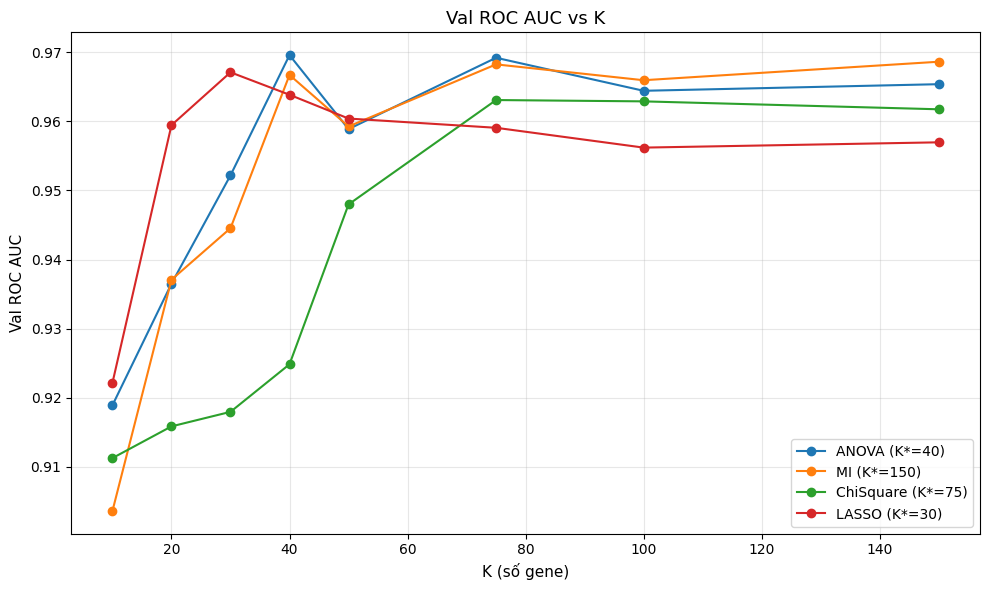

In [ ]:

methods = ['ANOVA', 'MI', 'ChiSquare', 'LASSO']
grid_results     = {m: [] for m in methods}
best_k_for_method = {}

# CHANGED: Updated criteria print statement
print("Tiêu chí: Val ROC AUC")
print(f"Quét K: {K_LIST}")
print("-" * 50)

for method in methods:
    # CHANGED: best_f2 to best_auc
    best_auc, opt_k = -1, K_LIST[0]
    print(f"\n[{method}]")

    for k in K_LIST:
        X_tr_k, X_va_k, _ = get_dataset_for_method_and_k(method, k)

        # CHANGED: val_f2 to val_auc
        _, val_auc = train_model(X_tr_k, y_train_s, X_va_k, y_val_s, is_grid_search=True)

        grid_results[method].append((k, val_auc))
        print(f"  K={k:<4} | Val AUC={val_auc:.4f}")

        if val_auc > best_auc:
            best_auc, opt_k = val_auc, k

    best_k_for_method[method] = opt_k
    print(f"  => K tối ưu = {opt_k} (Val AUC={best_auc:.4f})")

# Line plot
fig, ax = plt.subplots(figsize=(10, 6))
for method in methods:
    # CHANGED: f2s to aucs
    ks, aucs = zip(*grid_results[method])
    ax.plot(ks, aucs, marker='o', label=f"{method} (K*={best_k_for_method[method]})")

# CHANGED: Title, Y-axis label, and save filename
ax.set_title('Val ROC AUC vs K', fontsize=13)
ax.set_xlabel('K (số gene)', fontsize=11)
ax.set_ylabel('Val ROC AUC', fontsize=11)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

# Save with a new name reflecting AUC
plt.savefig(os.path.join(RESULT_DIR, "grid_search_auc.png"), dpi=150)
plt.show()

## 5. Đánh giá cuối — Test Set (1 lần duy nhất)

In [ ]:
from sklearn.metrics import roc_curve, classification_report, confusion_matrix

def evaluate_final(label, X_tr, y_tr, X_va, y_va, X_te, y_te):
    print(f"\n{'='*50}\n{label}\n{'='*50}")

    # CHANGED: Capture the best validation AUC from train_model
    model, best_val_auc = train_model(X_tr, y_tr, X_va, y_va, is_grid_search=False)
    print(f"  [Model Checkpoint] Best Val AUC: {best_val_auc:.4f}")

    # Get predictions on validation set
    vp, vl = get_probs(model, X_va, y_va)

    # --- THRESHOLD SELECTION ---
    # Option A: Keep using TARGET_SN (Recommended if minimum sensitivity is a strict business/medical rule)
    best_th = find_threshold(vl, vp, TARGET_SN)

    # Option B: Use Youden's J Statistic to find the mathematically optimal ROC threshold
    # fpr, tpr, thresholds = roc_curve(vl, vp)
    # best_th = thresholds[np.argmax(tpr - fpr)]
    # ---------------------------

    # Evaluate trên test
    tp, tl  = get_probs(model, X_te, y_te)
    tpreds  = (tp >= best_th).astype(int)
    m       = compute_metrics(tl, tpreds, tp)

    # Save Val AUC to the final metrics dictionary for later comparison
    m['Val_AUC'] = best_val_auc

    print(f"  Threshold (val): {best_th:.4f}")
    for k, v in m.items():
        print(f"  {k}: {v:.6f}")

    print("\nClassification Report:")
    print(classification_report(tl, tpreds, digits=4))
    print("Confusion Matrix:")
    print(confusion_matrix(tl, tpreds))

    return m

# ==========================================
# Run Evaluations
# ==========================================
final_results = {}

# Baseline
final_results['Baseline (211)'] = evaluate_final(
    'Baseline (211 Gene)',
    X_tr_std, y_train_s, X_va_std, y_val_s, X_te_std, y_test
)

# Từng phương pháp với K tối ưu
for method in methods:
    k_opt = best_k_for_method[method]
    X_tr_k, X_va_k, X_te_k = get_dataset_for_method_and_k(method, k_opt)

    final_results[f"{method} (K={k_opt})"] = evaluate_final(
        f"{method} (K={k_opt})",
        X_tr_k, y_train_s, X_va_k, y_val_s, X_te_k, y_test
    )


Baseline (211 Gene)
  [Model Checkpoint] Best Val AUC: 0.9713
  Threshold (val): 0.0874
  ACC: 0.857923
  Precision: 0.869159
  Sensitivity/Sn: 0.885714
  Specificity/Sp: 0.820513
  F1: 0.877358
  F2: 0.882353
  AUC: 0.942369
  Balanced Accuracy: 0.853114
  FN: 12.000000
  FP: 14.000000
  Val_AUC: 0.971314

Classification Report:
              precision    recall  f1-score   support

         0.0     0.8421    0.8205    0.8312        78
         1.0     0.8692    0.8857    0.8774       105

    accuracy                         0.8579       183
   macro avg     0.8556    0.8531    0.8543       183
weighted avg     0.8576    0.8579    0.8577       183

Confusion Matrix:
[[64 14]
 [12 93]]

ANOVA (K=40)
  [Model Checkpoint] Best Val AUC: 0.9600
  Threshold (val): 0.0298
  ACC: 0.792350
  Precision: 0.768000
  Sensitivity/Sn: 0.914286
  Specificity/Sp: 0.628205
  F1: 0.834783
  F2: 0.880734
  AUC: 0.921490
  Balanced Accuracy: 0.771245
  FN: 9.000000
  FP: 29.000000
  Val_AUC: 0.960031

C

In [ ]:
0res_df = pd.DataFrame(final_results).T
res_df.to_csv(os.path.join(RESULT_DIR, "final_metrics.csv"))

print("\n[TỔNG KẾT TEST METRICS]")
print(res_df[['Sensitivity/Sn', 'Specificity/Sp', 'F1', 'F2', 'AUC', 'Balanced Accuracy', 'FN', 'FP']].round(4))


[TỔNG KẾT TEST METRICS]
                  Sensitivity/Sn  Specificity/Sp      F1      F2     AUC  \
Baseline (211)            0.8857          0.8205  0.8774  0.8824  0.9424   
ANOVA (K=40)              0.9143          0.6282  0.8348  0.8807  0.9215   
MI (K=150)                0.8667          0.8718  0.8835  0.8733  0.9280   
ChiSquare (K=75)          0.8381          0.8333  0.8544  0.8445  0.9171   
LASSO (K=30)              0.9143          0.7436  0.8688  0.8955  0.9241   

                  Balanced Accuracy    FN    FP  
Baseline (211)               0.8531  12.0  14.0  
ANOVA (K=40)                 0.7712   9.0  29.0  
MI (K=150)                   0.8692  14.0  10.0  
ChiSquare (K=75)             0.8357  17.0  13.0  
LASSO (K=30)                 0.8289   9.0  20.0  
